# Pneumonia Classification on Chest X-rays


**Goal:** classify a chest X-ray as **NORMAL** or **PNEUMONIA** using image-processing techniques + deep learning.

## 0. Settings and reproducibility

In [1]:
import os, sys, json, random, re, shutil, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

QUICK_TEST   = False
SEED         = 42
IMG_SIZE     = 224        # images are resized to IMG_SIZE x IMG_SIZE
BATCH_SIZE   = 32
EPOCHS_CNN   = 25         # custom CNN (early stopping will stop sooner)
EPOCHS_HEAD  = 6          # transfer learning, stage 1 (frozen backbone)
EPOCHS_FT    = 14         # transfer learning, stage 2 (fine-tuning)
VAL_FRACTION = 0.15       # share of (train+val) used for validation, split BY PATIENT
USE_CLAHE    = True       # contrast enhancement (CLAHE) as a preprocessing step
PRETRAINED   = True       # ImageNet weights for the DenseNet121 model
OUT_DIR      = Path("/content/outputs")
FIG_DIR      = OUT_DIR / "figures"
# ------------------------------------------------

for d in (OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
import numpy as np
np.random.seed(SEED)
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU found:", gpus if gpus else "NONE  -> go to Runtime > Change runtime type and pick T4 GPU")

TensorFlow: 2.21.0
GPU found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Downloading the dataset
Dataset: **Chest X-Ray Images (Pneumonia)** by Paul Mooney on Kaggle (images originally from Kermany et al., 2018; paediatric patients, Guangzhou Women and Children's Medical Center).

In [3]:
import subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub", "kaggle", "python-docx", "opencv-python-headless"], check=False)

DATA_ROOT = None
if not QUICK_TEST:
    try:
        import kagglehub
        DATA_ROOT = Path(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
        print("Downloaded with kagglehub to:", DATA_ROOT)
    except Exception as e:
        print("kagglehub failed:", repr(e)[:200])
        from getpass import getpass
        tok = getpass("Paste your Kaggle API token (input hidden): ")
        os.environ["KAGGLE_API_TOKEN"] = tok          # new-style token
        os.environ["KAGGLE_KEY"] = tok                # old-style fallback
        dl = Path("/content/pneumonia_data"); dl.mkdir(exist_ok=True)
        subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                        "-p", str(dl), "--unzip"], check=True)
        DATA_ROOT = dl

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded with kagglehub to: /kaggle/input/chest-xray-pneumonia


In [4]:
def find_dataset_root(base):
    # It finds the folder that contains train/, test/ and val/
    for p in sorted(Path(base).rglob("train")):
        if "__MACOSX" in str(p): continue
        r = p.parent
        if (r/"test").is_dir() and (r/"val").is_dir():
            return r
    raise FileNotFoundError("Could not find train/test/val folders.")

if QUICK_TEST:
    DATASET_ROOT = Path(os.environ.get("FAKE_DATA_ROOT", "/content/fake_xray"))
else:
    DATASET_ROOT = find_dataset_root(DATA_ROOT)
print("Dataset root:", DATASET_ROOT)

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]          # label 0 = NORMAL, label 1 = PNEUMONIA
EXTS = {".jpg", ".jpeg", ".png"}

def list_files(split):
    rows = []
    for label, cname in enumerate(CLASS_NAMES):
        for p in sorted((DATASET_ROOT/split/cname).iterdir()):
            if p.suffix.lower() in EXTS and not p.name.startswith("."):
                rows.append((str(p), label))
    return rows

official = {s: list_files(s) for s in ("train", "val", "test")}
counts = {s: {c: sum(1 for _, l in official[s] if l == i) for i, c in enumerate(CLASS_NAMES)} for s in official}
for s in counts: print(f"{s:5s}", counts[s], " total =", sum(counts[s].values()))

Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray
train {'NORMAL': 1341, 'PNEUMONIA': 3875}  total = 5216
val   {'NORMAL': 8, 'PNEUMONIA': 8}  total = 16
test  {'NORMAL': 234, 'PNEUMONIA': 390}  total = 624


## 2. Explore the dataset
Two things matter here: (1) the classes are **imbalanced** (about 3 pneumonia images for every normal one in training), and (2) the official `val` folder has only **16 images**, far too few to monitor training reliably. That is why the original notebooks showed validation accuracy jumping between 0.33 and 0.96.

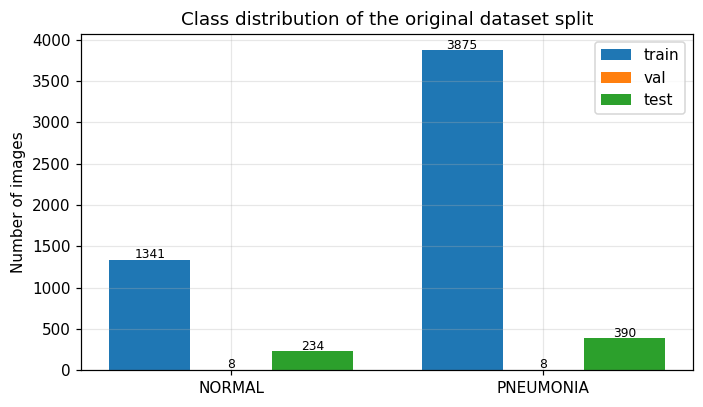

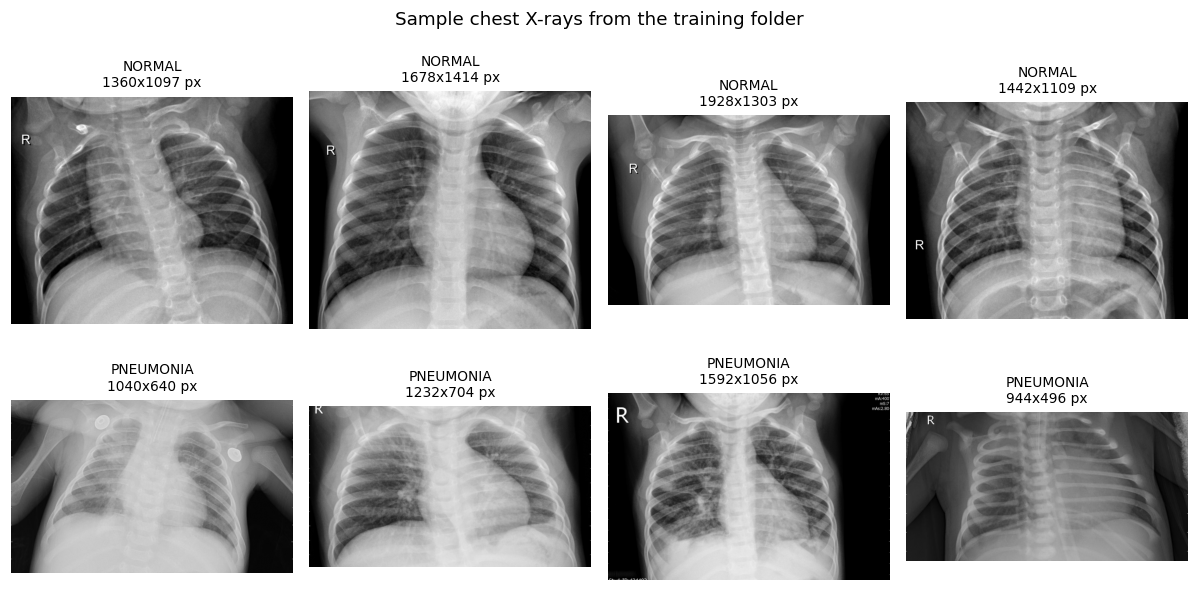

Image height  min/median/max: 177 899 2663
Image width   min/median/max: 445 1296 2637


In [5]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# Fig: class distribution in the official split
fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(2); w = 0.26
for k, s in enumerate(["train", "val", "test"]):
    vals = [counts[s][c] for c in CLASS_NAMES]
    bars = ax.bar(x + (k-1)*w, vals, w, label=s)
    for b, v in zip(bars, vals): ax.text(b.get_x()+b.get_width()/2, v+15, str(v), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES); ax.set_ylabel("Number of images")
ax.set_title("Class distribution of the original dataset split"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"fig_class_distribution.png", dpi=200); plt.show()

# Fig: random sample images
import cv2
rng = random.Random(SEED)
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for i, cname in enumerate(CLASS_NAMES):
    pool = [p for p, l in official["train"] if l == i]
    for j, p in enumerate(rng.sample(pool, 4)):
        im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        axes[i, j].imshow(im, cmap="gray"); axes[i, j].set_title(f"{cname}\n{im.shape[1]}x{im.shape[0]} px", fontsize=9)
        axes[i, j].axis("off")
plt.suptitle("Sample chest X-rays from the training folder"); plt.tight_layout()
plt.savefig(FIG_DIR/"fig_samples.png", dpi=200); plt.show()

# Image size statistics
sizes = np.array([cv2.imread(p, cv2.IMREAD_GRAYSCALE).shape for p, _ in rng.sample(official["train"], min(300, len(official["train"])))])
print("Image height  min/median/max:", sizes[:,0].min(), int(np.median(sizes[:,0])), sizes[:,0].max())
print("Image width   min/median/max:", sizes[:,1].min(), int(np.median(sizes[:,1])), sizes[:,1].max())

## 3. Build a reliable train / validation split (patient-wise)
* **Test set:** the official 624 test images are kept untouched and used **once**, at the very end.
* **Train + validation:** we merge the official `train` (5216) and `val` (16) images and re-split **about 85 / 15**.
* **Patient-wise:** the dataset contains several X-rays of the same patient (file names such as `person12_bacteria_45.jpeg` and `IM-0115-0001.jpeg`). If images of one patient land in both train and validation, the model can "recognise the patient" and the validation score looks better than it really is (*data leakage*). We therefore split **by patient ID**, keeping the class ratio similar.

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

def patient_id(path, label):
    name = Path(path).stem
    m = re.search(r"person(\d+)", name, re.I)          # PNEUMONIA: person12_bacteria_45
    if m: return f"P{label}_{m.group(1)}"
    m = re.search(r"IM-(\d+)", name, re.I)             # NORMAL: IM-0115-0001 / NORMAL2-IM-0373-0001
    if m: return f"N{label}_{m.group(1)}"
    return f"F{label}_{name}"                          # fallback: treat the file as its own patient

pool = official["train"] + official["val"]
paths  = np.array([p for p, _ in pool]); labels = np.array([l for _, l in pool])
groups = np.array([patient_id(p, l) for p, l in pool])
print("Images:", len(paths), "| distinct patient groups:", len(set(groups)))

n_splits = max(2, int(round(1 / VAL_FRACTION)))
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(paths, labels, groups))
assert not (set(groups[tr_idx]) & set(groups[va_idx])), "patient leakage!"

train_files = [(paths[i], int(labels[i])) for i in tr_idx]
val_files   = [(paths[i], int(labels[i])) for i in va_idx]
test_files  = official["test"]

def cnt(fs):
    a = np.array([l for _, l in fs]); return {"NORMAL": int((a==0).sum()), "PNEUMONIA": int((a==1).sum()), "total": len(a)}
split_counts = {"train": cnt(train_files), "val": cnt(val_files), "test": cnt(test_files)}
for k, v in split_counts.items(): print(f"{k:5s}", v)

Images: 5232 | distinct patient groups: 2650
train {'NORMAL': 1170, 'PNEUMONIA': 3319, 'total': 4489}
val   {'NORMAL': 179, 'PNEUMONIA': 564, 'total': 743}
test  {'NORMAL': 234, 'PNEUMONIA': 390, 'total': 624}


## 4. Image-processing pipeline
Each image goes through the same steps:

1. **Grayscale** reading (X-rays are single-channel).
2. **CLAHE** (Contrast Limited Adaptive Histogram Equalization): improves local contrast so that lung opacities stand out (clip limit 2.0, 8x8 tiles).
3. **Resize** to 224 x 224 (bilinear/area interpolation).
4. **Normalisation** to the [0, 1] range happens inside the model (`Rescaling`), so the same code is used for training and prediction.

All images are loaded once into memory as `uint8` arrays, which makes training fast.

Loaded in 154s -> (4489, 224, 224, 1) (743, 224, 224, 1) (624, 224, 224, 1)


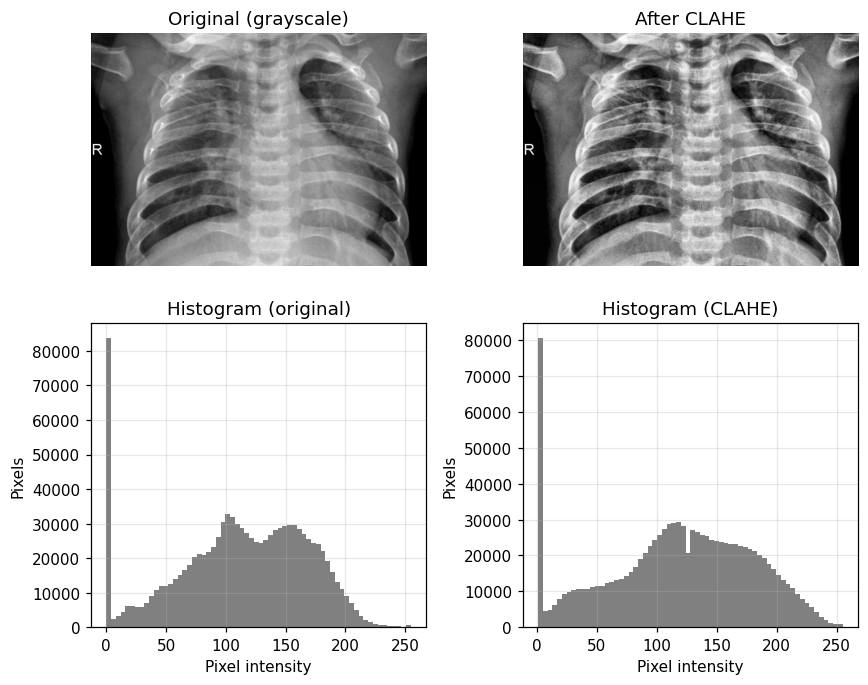

In [7]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_image(path, use_clahe=USE_CLAHE, size=IMG_SIZE):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None: raise IOError(path)
    if use_clahe: im = clahe.apply(im)
    return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)

def load_set(files):
    X = np.stack([preprocess_image(p) for p, _ in files]).astype("uint8")[..., None]
    y = np.array([l for _, l in files], dtype="float32")
    return X, y

if QUICK_TEST:                      # tiny subsets only for debugging
    train_files, val_files, test_files = train_files[:96], val_files[:32], test_files[:48]

t0 = time.time()
X_train, y_train = load_set(train_files)
X_val,   y_val   = load_set(val_files)
X_test,  y_test  = load_set(test_files)
print(f"Loaded in {time.time()-t0:.0f}s ->", X_train.shape, X_val.shape, X_test.shape)

# Fig: effect of preprocessing (original vs CLAHE) + histograms
sample_path = next(p for p, l in train_files if l == 1)
raw  = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
enh  = clahe.apply(raw)
fig, ax = plt.subplots(2, 2, figsize=(8, 6.5))
ax[0,0].imshow(raw, cmap="gray"); ax[0,0].set_title("Original (grayscale)"); ax[0,0].axis("off")
ax[0,1].imshow(enh, cmap="gray"); ax[0,1].set_title("After CLAHE"); ax[0,1].axis("off")
ax[1,0].hist(raw.ravel(), 64, color="gray"); ax[1,0].set_title("Histogram (original)")
ax[1,1].hist(enh.ravel(), 64, color="gray"); ax[1,1].set_title("Histogram (CLAHE)")
for a in ax[1]: a.set_xlabel("Pixel intensity"); a.set_ylabel("Pixels")
plt.tight_layout(); plt.savefig(FIG_DIR/"fig_preprocessing.png", dpi=200); plt.show()

## 5. Data augmentation and class weights
* **Augmentation** (training only): small rotation (±5°), shifts (±5 %), zoom (±10 %) and contrast jitter. We do **not** flip images horizontally: the heart is on the left side in real X-rays, so mirrored images are unrealistic.
* **Class weights:** because pneumonia images outnumber normal images, each normal image gets a higher weight in the loss so that the model does not simply predict "pneumonia" every time.
* The validation and test pipelines are **never shuffled** (this keeps labels and predictions aligned for the metrics).

NORMAL: 1170  PNEUMONIA: 3319  class weights: {0: 1.918, 1: 0.676}


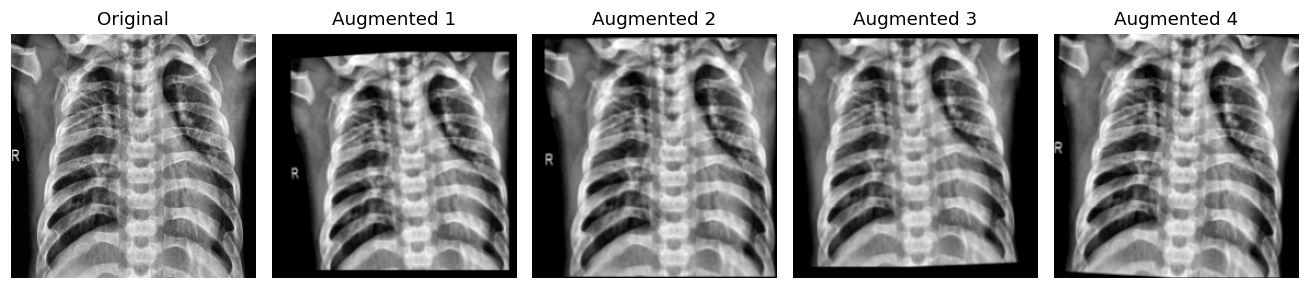

In [8]:
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
print("NORMAL:", n_neg, " PNEUMONIA:", n_pos, " class weights:", {k: round(v, 3) for k, v in class_weight.items()})

def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training: ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(X_train, y_train, True), make_ds(X_val, y_val, False), make_ds(X_test, y_test, False)

def make_augment():
    L = tf.keras.layers
    return tf.keras.Sequential([
        L.RandomRotation(5/360.0, fill_mode="constant"),
        L.RandomTranslation(0.05, 0.05, fill_mode="constant"),
        L.RandomZoom(0.10, fill_mode="constant"),
        L.RandomContrast(0.15),
    ], name="augmentation")

# Figure: augmentation examples
aug = make_augment()
base_img = X_train[np.where(y_train == 1)[0][0]][None].astype("float32")
fig, ax = plt.subplots(1, 5, figsize=(12, 2.8))
ax[0].imshow(base_img[0, ..., 0], cmap="gray", vmin=0, vmax=255); ax[0].set_title("Original")
for i in range(1, 5):
    ax[i].imshow(aug(base_img, training=True)[0, ..., 0], cmap="gray", vmin=0, vmax=255); ax[i].set_title(f"Augmented {i}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR/"fig_augmentation.png", dpi=200); plt.show()

## 6. The two models
We compare two classifiers:

* **Model A: custom CNN** (4 convolution blocks: Conv → BatchNorm → ReLU → MaxPool, then Global Average Pooling, Dropout and a sigmoid output). Trained from scratch. This is the "baseline".
* **Model B: DenseNet121 transfer learning.** DenseNet121 pre-trained on ImageNet is the backbone also used by the well-known CheXNet paper. Stage 1 trains only the new classification head; stage 2 fine-tunes the last part of the backbone with a very small learning rate. (BatchNorm layers stay frozen, which keeps fine-tuning stable.)

Both models output one number between 0 and 1 = the probability of **PNEUMONIA**. Each is split into `pre` (preprocessing + augmentation), `features` (feature extractor) and `head` (classifier).

In [9]:
L = tf.keras.layers
S = IMG_SIZE

def build_custom_cnn():
    inp = L.Input((S, S, 1))
    x = make_augment()(inp)
    x = L.Rescaling(1/255.)(x)
    pre = tf.keras.Model(inp, x, name="pre_A")

    fin = L.Input((S, S, 1))
    f = fin
    for filters in (32, 64, 128, 256):
        f = L.Conv2D(filters, 3, padding="same", use_bias=False)(f)
        f = L.BatchNormalization()(f); f = L.ReLU()(f)
        f = L.MaxPooling2D(2)(f)
    features = tf.keras.Model(fin, f, name="features_A")

    head = tf.keras.Sequential([L.Input(features.output_shape[1:]),
                                L.GlobalAveragePooling2D(), L.Dropout(0.4),
                                L.Dense(64, activation="relu"), L.Dropout(0.4),
                                L.Dense(1, activation="sigmoid")], name="head_A")
    inp2 = L.Input((S, S, 1))
    full = tf.keras.Model(inp2, head(features(pre(inp2))), name="Custom_CNN")
    return dict(name="Custom CNN", full=full, pre=pre, features=features, head=head)

def build_densenet():
    inp = L.Input((S, S, 1))
    x = make_augment()(inp)
    x = L.Concatenate()([x, x, x])                         # gray -> 3 channels for the ImageNet backbone
    x = L.Rescaling(1/255.)(x)
    x = L.Normalization(mean=[0.485, 0.456, 0.406], variance=[0.229**2, 0.224**2, 0.225**2])(x)
    pre = tf.keras.Model(inp, x, name="pre_B")

    base = tf.keras.applications.DenseNet121(include_top=False,
                weights="imagenet" if PRETRAINED else None, input_shape=(S, S, 3))
    head = tf.keras.Sequential([L.Input(base.output_shape[1:]),
                                L.GlobalAveragePooling2D(), L.Dropout(0.4),
                                L.Dense(64, activation="relu"), L.Dropout(0.3),
                                L.Dense(1, activation="sigmoid")], name="head_B")
    inp2 = L.Input((S, S, 1))
    full = tf.keras.Model(inp2, head(base(pre(inp2))), name="DenseNet121_TL")
    return dict(name="DenseNet121 (transfer learning)", full=full, pre=pre, features=base, head=head)

def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                           tf.keras.metrics.Precision(name="precision"),
                           tf.keras.metrics.Recall(name="recall"),
                           tf.keras.metrics.AUC(name="auc")])

A = build_custom_cnn()
A["full"].summary(line_length=100)
print("Parameters:", f"{A['full'].count_params():,}")

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)                 │ (None, 224, 224, 1)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ pre_A (Functional)                         │ (None, 224, 224, 1)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ features_A (Functional)                    │ (None, 14, 14, 256)             │           389,280 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ head_A (Sequential)                        │ (None, 1)                       │            16,513 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 405,793 (1.55 MB)

 Trainable params: 404,833 (1.54 MB)

 Non-trainable params: 960 (3.75 KB)

Parameters: 405,793


## 7. Train Model A (custom CNN)
`EarlyStopping` stops when the validation loss stops improving and restores the best weights; `ReduceLROnPlateau` lowers the learning rate when progress stalls.

In [10]:
def make_callbacks(patience):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=max(1, patience//2), min_lr=1e-6, verbose=1)]

epochs_A = 1 if QUICK_TEST else EPOCHS_CNN
compile_model(A["full"], 1e-3)
t0 = time.time()
histA = A["full"].fit(train_ds, validation_data=val_ds, epochs=epochs_A, class_weight=class_weight,
                      callbacks=make_callbacks(5), verbose=2)
timeA = time.time() - t0
histA = histA.history
print(f"Model A trained in {timeA/60:.1f} min, {len(histA['loss'])} epochs")
A["full"].save(OUT_DIR / "model_custom_cnn.keras")

Epoch 1/25
141/141 - 29s - 206ms/step - accuracy: 0.8347 - auc: 0.9164 - loss: 0.3659 - precision: 0.9485 - recall: 0.8210 - val_accuracy: 0.7591 - val_auc: 0.5000 - val_loss: 1.5926 - val_precision: 0.7591 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/25
141/141 - 17s - 119ms/step - accuracy: 0.8797 - auc: 0.9523 - loss: 0.2749 - precision: 0.9621 - recall: 0.8716 - val_accuracy: 0.7591 - val_auc: 0.5000 - val_loss: 1.8414 - val_precision: 0.7591 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/25

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
141/141 - 17s - 123ms/step - accuracy: 0.9029 - auc: 0.9645 - loss: 0.2372 - precision: 0.9703 - recall: 0.8961 - val_accuracy: 0.7591 - val_auc: 0.5000 - val_loss: 2.5218 - val_precision: 0.7591 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/25
141/141 - 17s - 122ms/step - accuracy: 0.9254 - auc: 0.9768 - loss: 0.1908 - precision: 0.9782 - recall: 0.9196 - val_accuracy: 0.7591 - val_auc: 0.5615 - v

## 8. Train Model B (DenseNet121, two stages)

In [11]:
B = build_densenet()
base = B["features"]
epochs_head, epochs_ft = (1, 1) if QUICK_TEST else (EPOCHS_HEAD, EPOCHS_FT)

# ---- Stage 1: frozen backbone, train the head only ----
base.trainable = False
compile_model(B["full"], 1e-3)
t0 = time.time()
h1 = B["full"].fit(train_ds, validation_data=val_ds, epochs=epochs_head, class_weight=class_weight,
                   callbacks=make_callbacks(3), verbose=2).history

# ---- Stage 2: unfreeze the last layers of the backbone (BatchNorm stays frozen) ----
base.trainable = True
n_unfreeze = 120
for layer in base.layers[:-n_unfreeze]: layer.trainable = False
for layer in base.layers:
    if isinstance(layer, L.BatchNormalization): layer.trainable = False
compile_model(B["full"], 3e-5)
h2 = B["full"].fit(train_ds, validation_data=val_ds, epochs=epochs_ft, class_weight=class_weight,
                   callbacks=make_callbacks(4), verbose=2).history
timeB = time.time() - t0

histB = {k: h1[k] + h2[k] for k in h1 if k in h2}
stageB_boundary = len(h1["loss"])
print(f"Model B trained in {timeB/60:.1f} min (stage 1: {stageB_boundary} epochs, stage 2: {len(h2['loss'])} epochs)")
B["full"].save(OUT_DIR / "model_densenet121.keras")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
141/141 - 55s - 387ms/step - accuracy: 0.7819 - auc: 0.8669 - loss: 0.4591 - precision: 0.9179 - recall: 0.7743 - val_accuracy: 0.9515 - val_auc: 0.9885 - val_loss: 0.1395 - val_precision: 0.9664 - val_recall: 0.9699 - learning_rate: 0.0010
Epoch 2/6
141/141 - 22s - 159ms/step - accuracy: 0.8719 - auc: 0.9458 - loss: 0.2969 - precision: 0.9534 - recall: 0.8692 - val_accuracy: 0.9475 - val_auc: 0.9887 - val_loss: 0.1377 - val_precision: 0.9747 - val_recall: 0.9557 - learning_rate: 0.0010
Epoch 3/6

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
141/141 - 22s - 155ms/step - accuracy: 0.8900 - auc: 0.9539 - loss: 0.2752 - precision: 0.9627 - recall: 0.8855 - val_accuracy: 0.9381 - val_auc: 0.9889 - val_loss: 0.1391 - val_precision: 0.9796 - val_recall: 0.9379 - learning_rate: 0.0010
Epoch 4/6
141/141 - 22s - 157ms/step - accuracy: 0.8953 - auc: 0.9609 - loss: 0.2514 - precision: 0.9633 - recall: 0.89

## 9. Evaluation
* Metrics are computed on the **untouched official test set** (624 images) and on the validation set.
* Besides the default threshold 0.5, we also report a **validation-tuned threshold** (Youden's J = sensitivity + specificity − 1, chosen on the *validation* set, never on the test set). Because the official test set differs from the training data, and a threshold of 0.5 usually gives too many false alarms on it.
* The final model is **selected using validation AUC**, not test results.

In [12]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay

def compute_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    prec = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2 * prec * sens / (prec + sens) if prec + sens else 0.0
    auc = roc_auc_score(y, p) if len(set(y.tolist())) > 1 else float("nan")
    return dict(threshold=float(thr), accuracy=float((tp+tn)/len(y)), precision=float(prec), recall=float(sens),
                specificity=float(spec), f1=float(f1), auc=float(auc), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    j = tpr - fpr
    t = thr[int(np.argmax(j))]
    return float(min(max(t, 0.0), 1.0))

MODELS = {"A": A, "B": B}
HIST   = {"A": histA, "B": histB}
RES = {}
for key, M in MODELS.items():
    pv = M["full"].predict(X_val,  batch_size=64, verbose=0).ravel()
    pt = M["full"].predict(X_test, batch_size=64, verbose=0).ravel()
    thr = youden_threshold(y_val, pv)
    M.update(p_val=pv, p_test=pt, thr=thr)
    RES[key] = dict(name=M["name"],
                    val=compute_metrics(y_val, pv, 0.5),
                    test_05=compute_metrics(y_test, pt, 0.5),
                    test_tuned=compute_metrics(y_test, pt, thr),
                    params=int(M["full"].count_params()))

import pandas as pd
rows = []
for key in RES:
    for tag, label in (("val", "Validation, thr 0.5"), ("test_05", "Test, thr 0.5"), ("test_tuned", f"Test, tuned thr")):
        m = RES[key][tag]
        rows.append([RES[key]["name"], label, round(m["threshold"], 3), m["accuracy"], m["precision"], m["recall"], m["specificity"], m["f1"], m["auc"]])
summary_df = pd.DataFrame(rows, columns=["Model", "Evaluated on", "Threshold", "Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"]).round(4)
summary_df.to_csv(OUT_DIR / "metrics_summary.csv", index=False)
summary_df

,Model,Evaluated on,Threshold,Accuracy,Precision,Recall,Specificity,F1,AUC
0,Custom CNN,"Validation, thr 0.5",0.500,0.9596,0.9668,0.9805,0.8939,0.9736,0.9924
1,Custom CNN,"Test, thr 0.5",0.500,0.7917,0.7539,0.9897,0.4615,0.8559,0.9430
2,Custom CNN,"Test, tuned thr",0.782,0.8429,0.8106,0.9769,0.6197,0.8860,0.9430
3,DenseNet121 (transfer learning),"Validation, thr 0.5",0.500,0.9771,0.9875,0.9823,0.9609,0.9849,0.9977
4,DenseNet121 (transfer learning),"Test, thr 0.5",0.500,0.8574,0.8182,0.9923,0.6325,0.8969,0.9726
5,DenseNet121 (transfer learning),"Test, tuned thr",0.873,0.8942,0.8616,0.9897,0.7350,0.9212,0.9726


Selected final model: DenseNet121 (transfer learning) | validation AUC = 0.9977


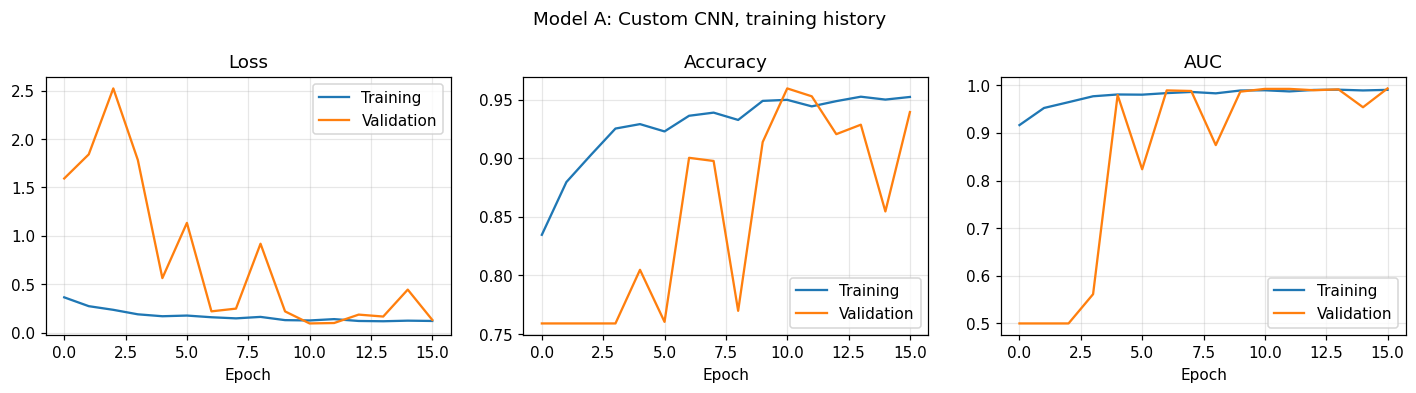

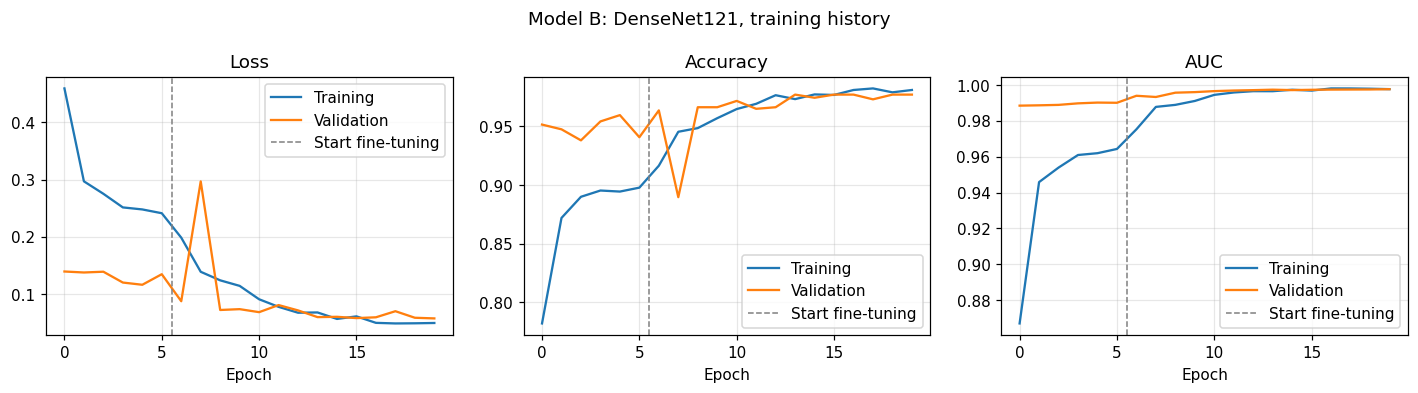

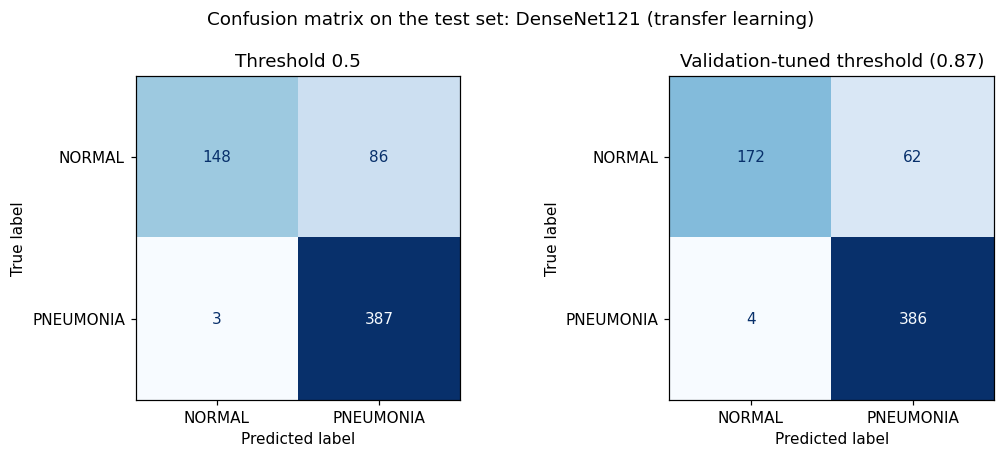

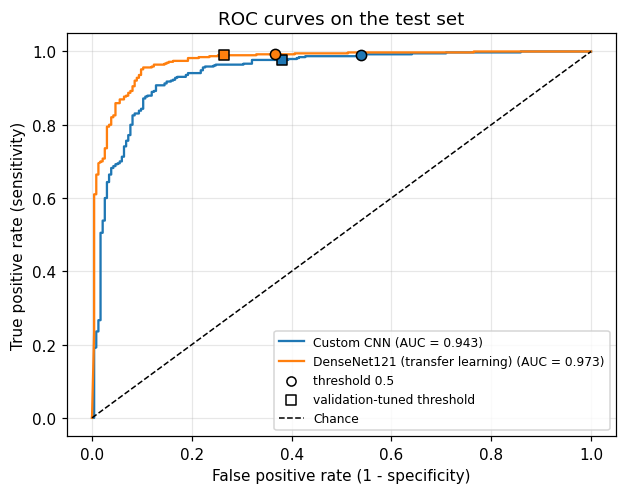

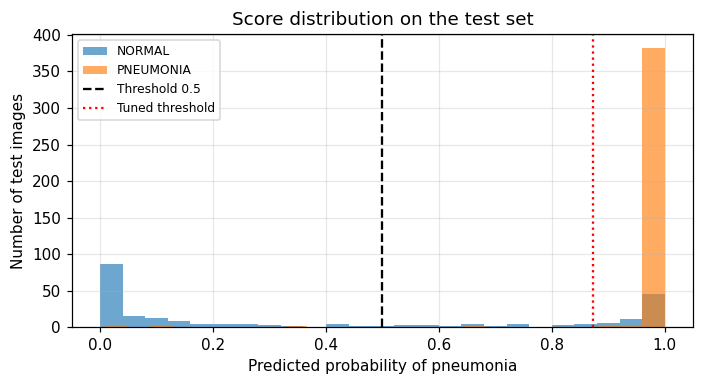

              precision    recall  f1-score   support

      NORMAL      0.980     0.632     0.769       234
   PNEUMONIA      0.818     0.992     0.897       390

    accuracy                          0.857       624
   macro avg      0.899     0.812     0.833       624
weighted avg      0.879     0.857     0.849       624



In [13]:
# Select the final model with VALIDATION AUC (never with test results)
best_key = max(RES, key=lambda k: (RES[k]["val"]["auc"], RES[k]["val"]["f1"]))
BEST = MODELS[best_key]
print("Selected final model:", BEST["name"], "| validation AUC =", round(RES[best_key]["val"]["auc"], 4))

# ---- Figure: training curves for both models ----
def plot_history(h, title, fname, boundary=None):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for a, (m, t) in zip(ax, [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]):
        a.plot(h[m], label="Training"); a.plot(h["val_" + m], label="Validation")
        if boundary: a.axvline(boundary - 0.5, color="gray", ls="--", lw=1, label="Start fine-tuning")
        a.set_title(t); a.set_xlabel("Epoch"); a.legend()
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=200); plt.show()

plot_history(histA, "Model A: Custom CNN, training history", "fig_history_A.png")
plot_history(histB, "Model B: DenseNet121, training history", "fig_history_B.png", stageB_boundary)

# ---- Figure: confusion matrices of the selected model ----
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, tag, ttl in zip(ax, ["test_05", "test_tuned"], ["Threshold 0.5", f"Validation-tuned threshold ({BEST['thr']:.2f})"]):
    m = RES[best_key][tag]
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=a, cmap="Blues", values_format="d", colorbar=False)
    a.set_title(ttl); a.grid(False)
fig.suptitle(f"Confusion matrix on the test set: {BEST['name']}"); plt.tight_layout()
plt.savefig(FIG_DIR / "fig_confusion_matrix.png", dpi=200); plt.show()

# ---- Figure: ROC curves (test set) ----
plt.figure(figsize=(5.8, 4.6))
for key, M in MODELS.items():
    fpr, tpr, _ = roc_curve(y_test, M["p_test"])
    ln, = plt.plot(fpr, tpr, label=f"{M['name']} (AUC = {RES[key]['test_05']['auc']:.3f})")
    for tag, mk in (("test_05", "o"), ("test_tuned", "s")):          # operating points
        plt.scatter(1 - RES[key][tag]["specificity"], RES[key][tag]["recall"], marker=mk, s=45, color=ln.get_color(), edgecolor="k", zorder=5)
plt.scatter([], [], marker="o", color="w", edgecolor="k", label="threshold 0.5")
plt.scatter([], [], marker="s", color="w", edgecolor="k", label="validation-tuned threshold")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
plt.xlabel("False positive rate (1 - specificity)"); plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right", fontsize=8); plt.tight_layout()
plt.savefig(FIG_DIR / "fig_roc.png", dpi=200); plt.show()

# ---- Figure: score distribution of the selected model (test) ----
plt.figure(figsize=(6.5, 3.6))
plt.hist(BEST["p_test"][y_test == 0], 25, alpha=0.65, label="NORMAL")
plt.hist(BEST["p_test"][y_test == 1], 25, alpha=0.65, label="PNEUMONIA")
plt.axvline(0.5, color="k", ls="--", label="Threshold 0.5")
plt.axvline(BEST["thr"], color="r", ls=":", label="Tuned threshold")
plt.xlabel("Predicted probability of pneumonia"); plt.ylabel("Number of test images")
plt.title("Score distribution on the test set"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(FIG_DIR / "fig_score_distribution.png", dpi=200); plt.show()

from sklearn.metrics import classification_report
print(classification_report(y_test, (BEST["p_test"] >= 0.5).astype(int), target_names=CLASS_NAMES, digits=3))

## 10. Explaining the predictions (Grad-CAM) and looking at errors
**Grad-CAM** highlights the image regions that pushed the model towards "pneumonia". If the heat-map lies on the lungs, the model uses medically sensible evidence; if it lies on text markers or borders, it is a warning sign.

{'True positive (pneumonia found)': 386, 'True negative (normal found)': 172, 'False positive (false alarm)': 62, 'False negative (missed pneumonia)': 4}


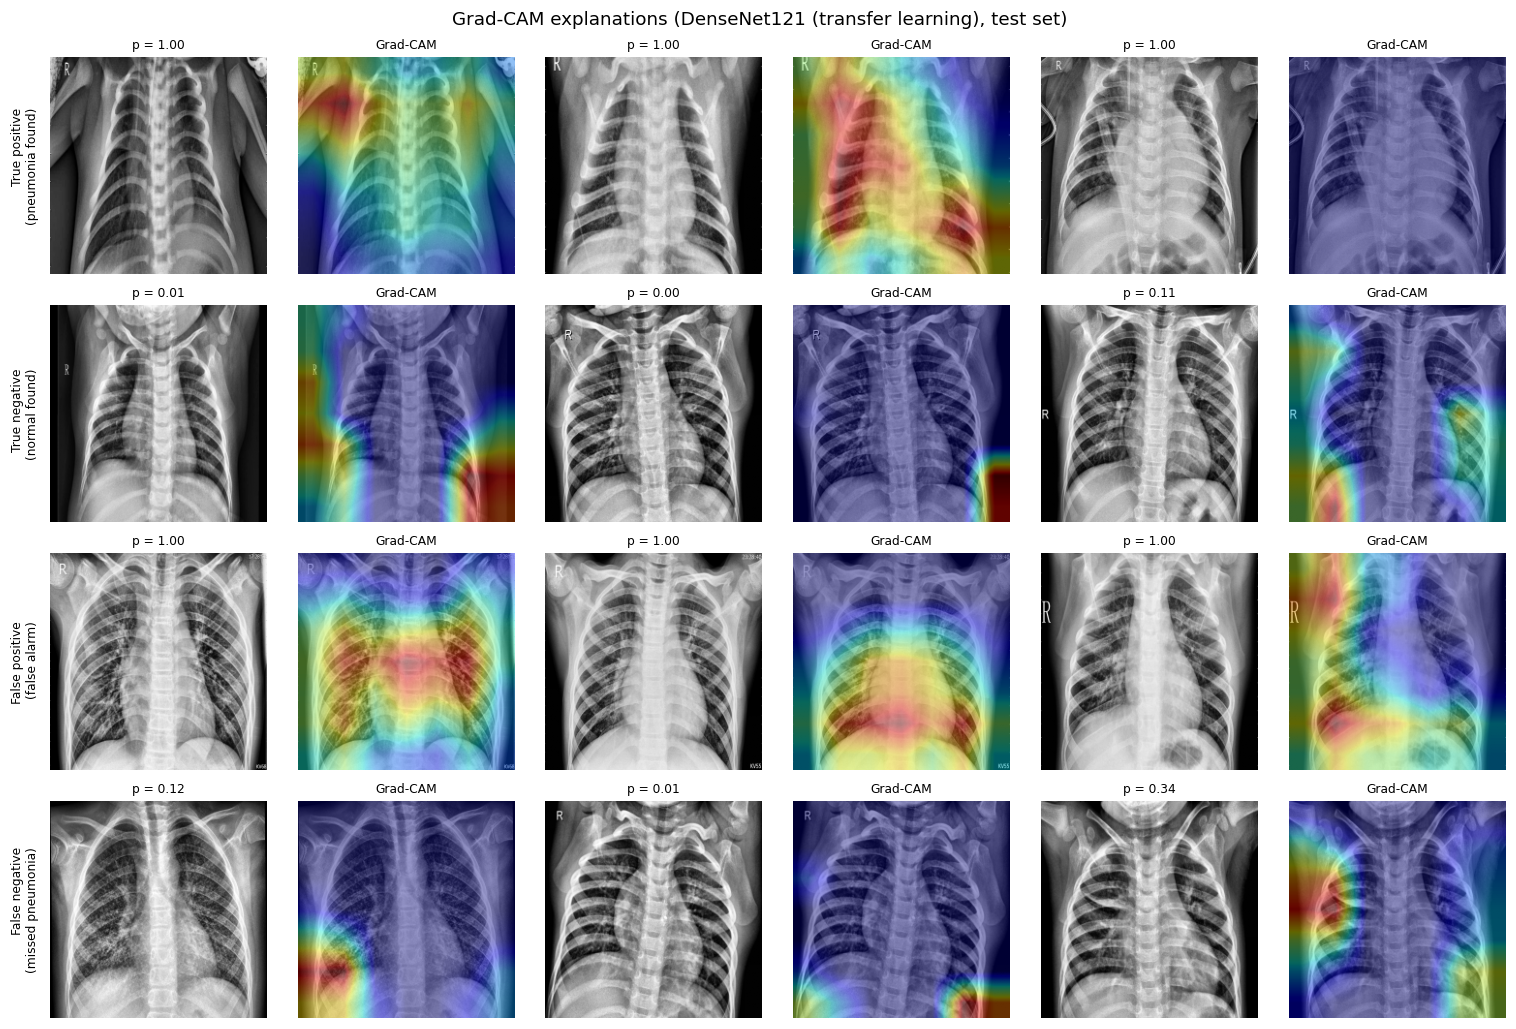

In [14]:
def grad_cam(parts, img_uint8):
    x = tf.convert_to_tensor(img_uint8[None].astype("float32"))
    x = parts["pre"](x, training=False)
    with tf.GradientTape() as tape:
        fmap = parts["features"](x, training=False)
        tape.watch(fmap)
        score = parts["head"](fmap, training=False)[:, 0]
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0].numpy()
    return cam / (cam.max() + 1e-8)

pred_cls = (BEST["p_test"] >= BEST["thr"]).astype(int)
groups_idx = {
    "True positive (pneumonia found)":  np.where((y_test == 1) & (pred_cls == 1))[0],
    "True negative (normal found)":     np.where((y_test == 0) & (pred_cls == 0))[0],
    "False positive (false alarm)":     np.where((y_test == 0) & (pred_cls == 1))[0],
    "False negative (missed pneumonia)": np.where((y_test == 1) & (pred_cls == 0))[0],
}
print({k: len(v) for k, v in groups_idx.items()})

n_show = 3
fig, axes = plt.subplots(len(groups_idx), n_show * 2, figsize=(14, 9.5))
rs = np.random.RandomState(SEED)
for r, (gname, idxs) in enumerate(groups_idx.items()):
    chosen = rs.choice(idxs, size=min(n_show, len(idxs)), replace=False) if len(idxs) else []
    for c in range(n_show):
        a1, a2 = axes[r, 2*c], axes[r, 2*c + 1]
        a1.axis("off"); a2.axis("off")
        if c >= len(chosen): continue
        i = int(chosen[c]); img = X_test[i]
        cam = cv2.resize(grad_cam(BEST, img), (S, S))
        a1.imshow(img[..., 0], cmap="gray"); a1.set_title(f"p = {BEST['p_test'][i]:.2f}", fontsize=8)
        a2.imshow(img[..., 0], cmap="gray"); a2.imshow(cam, cmap="jet", alpha=0.4); a2.set_title("Grad-CAM", fontsize=8)
        if c == 0: a1.text(-0.05, 0.5, gname.replace(" (", "\n("), transform=a1.transAxes, rotation=90, va="center", ha="right", fontsize=8)
fig.suptitle(f"Grad-CAM explanations ({BEST['name']}, test set)"); plt.tight_layout()
plt.savefig(FIG_DIR / "fig_gradcam.png", dpi=200); plt.show()

### Occlusion testing
A second, model-agnostic way to see what the network uses: a grey square is slid over the image and, at every position, we measure how much the prediction changes. Regions where hiding the image content **reduces confidence in the predicted class** are the ones the network relies on. Unlike Grad-CAM this needs no gradients, only repeated predictions.

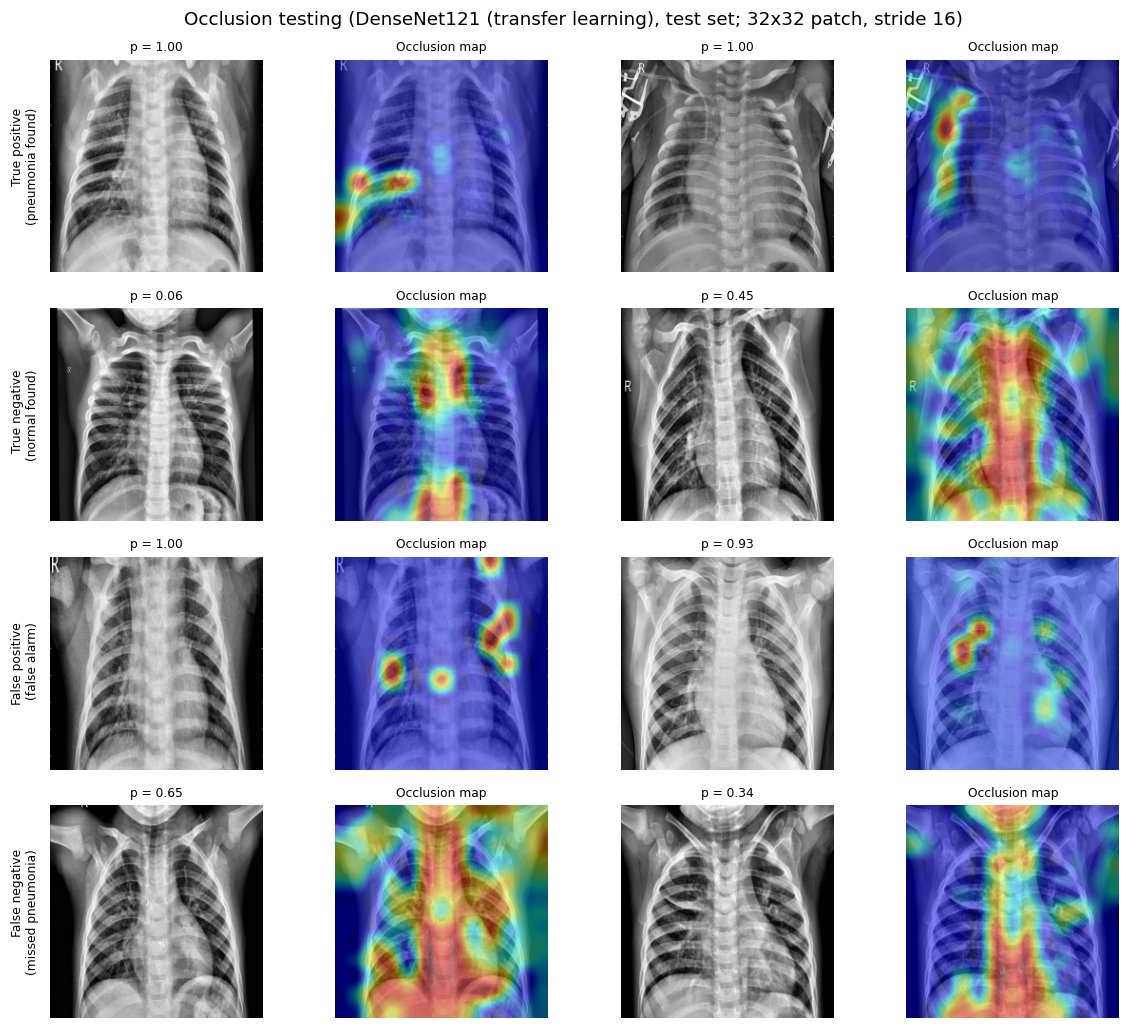

In [15]:
def occlusion_map(model, img, patch=32, stride=16):
    base = float(model.predict(img[None].astype("float32"), verbose=0)[0, 0])
    pos = list(range(0, S - patch + 1, stride)); n = len(pos)
    fill = np.uint8(img.mean()); batch = []
    for y in pos:
        for x in pos:
            im = img.copy(); im[y:y+patch, x:x+patch] = fill; batch.append(im)
    probs = model.predict(np.stack(batch).astype("float32"), batch_size=128, verbose=0).ravel().reshape(n, n)
    pred_pos = base >= BEST["thr"]
    imp = (base - probs) if pred_pos else (probs - base)        # evidence FOR the predicted class
    imp = np.clip(imp, 0, None)
    imp = cv2.resize(imp, (S, S), interpolation=cv2.INTER_CUBIC)
    return base, imp / (imp.max() + 1e-8)

rs2 = np.random.RandomState(SEED + 1); n_occ = 2
fig, axes = plt.subplots(len(groups_idx), n_occ * 2, figsize=(11, 9.5))
for r, (gname, idxs) in enumerate(groups_idx.items()):
    chosen = rs2.choice(idxs, size=min(n_occ, len(idxs)), replace=False) if len(idxs) else []
    for c in range(n_occ):
        a1, a2 = axes[r, 2*c], axes[r, 2*c + 1]; a1.axis("off"); a2.axis("off")
        if c >= len(chosen): continue
        i = int(chosen[c]); base_p, imp = occlusion_map(BEST["full"], X_test[i])
        a1.imshow(X_test[i][..., 0], cmap="gray"); a1.set_title(f"p = {base_p:.2f}", fontsize=8)
        a2.imshow(X_test[i][..., 0], cmap="gray"); a2.imshow(imp, cmap="jet", alpha=0.45); a2.set_title("Occlusion map", fontsize=8)
        if c == 0: a1.text(-0.05, 0.5, gname.replace(" (", "\n("), transform=a1.transAxes, rotation=90, va="center", ha="right", fontsize=8)
fig.suptitle(f"Occlusion testing ({BEST['name']}, test set; 32x32 patch, stride 16)"); plt.tight_layout()
plt.savefig(FIG_DIR / "fig_occlusion.png", dpi=200); plt.show()

## 11. Save all numbers for the report

In [16]:
RESULTS = dict(
    config=dict(seed=SEED, img_size=IMG_SIZE, batch_size=BATCH_SIZE, clahe=USE_CLAHE, pretrained=PRETRAINED,
                epochs_cnn=len(histA["loss"]), epochs_B=len(histB["loss"])),
    official_counts=counts, split_counts=split_counts, class_weight={str(k): float(v) for k, v in class_weight.items()},
    patients_groups=int(len(set(groups))), models=RES, best=best_key, best_name=BEST["name"], best_threshold=BEST["thr"],
    train_minutes=dict(A=round(timeA/60, 1), B=round(timeB/60, 1)),
    image_stats=dict(h_min=int(sizes[:,0].min()), h_med=int(np.median(sizes[:,0])), h_max=int(sizes[:,0].max()),
                     w_min=int(sizes[:,1].min()), w_med=int(np.median(sizes[:,1])), w_max=int(sizes[:,1].max())),
)
with open(OUT_DIR / "results.json", "w") as f: json.dump(RESULTS, f, indent=2)
print(json.dumps({k: RESULTS[k] for k in ("best_name", "best_threshold", "train_minutes")}, indent=2))

{
  "best_name": "DenseNet121 (transfer learning)",
  "best_threshold": 0.8728266954421997,
  "train_minutes": {
    "A": 4.7,
    "B": 9.2
  }
}
